# ATML PA3 — Task 1: LLM Fine-Tuning (Full FT, L2-SP, LoRA-4, LoRA-16, OPLoRA-16)

**How to use this notebook**
1. Runtime → Change runtime type → **GPU** (A100 / L4 is fastest; a T4 works but is slower). Everything is FP16, as the assignment requires.
2. Run all cells top to bottom. **If the session disconnects, just reconnect and "Run all" again.** Every stage checks Google Drive and skips work that is already finished:
   * data preparation is cached,
   * training resumes from the latest checkpoint (model / adapters, optimizer, scheduler, grad-scaler, RNG and data position),
   * every benchmark of every evaluation condition is saved separately,
   * diagnostics and qualitative generations are saved per condition.
3. You can run only some training runs per session by editing `RUNS_TO_TRAIN` in the config cell.

**Drive space.** A Full-FT resume state (FP32 weights + AdamW moments) is about 7 GB. It is written only at the four required recovery points, at most one exists at a time, and it is deleted when the run finishes. Files deleted through the Drive mount go to Drive's **Trash** and still count against your quota, so the notebook signs in to the Drive API once per session and permanently deletes its own trashed `resume_u*.pt` files (`PURGE_DRIVE_TRASH`). Keep ~9 GB free while a Full-FT run is training.

All outputs go to `MyDrive/ATML_PA3/task1/`.

In [ ]:
# 0. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# 1. Install dependencies (re-run after every reconnect; Colab VMs are fresh)
!pip -q install "transformers>=4.51,<5" "accelerate>=0.30" "datasets>=2.19,<4" "lm_eval[hf]>=0.4.8,<0.5" safetensors pyyaml pandas matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 wh

In [ ]:
# 2. Imports, paths and configuration
import os, json, math, time, random, re, gc, shutil, glob, unicodedata, gzip, types
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.checkpoint import checkpoint as torch_checkpoint

os.environ["HF_DATASETS_TRUST_REMOTE_CODE"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

ROOT = Path("/content/drive/MyDrive/ATML_PA3/task1")   # persistent (Drive)
LOCAL = Path("/content/task1_local")                    # fast scratch (lost on disconnect)
for d in [ROOT, LOCAL, ROOT / "data", ROOT / "runs", ROOT / "eval", ROOT / "qualitative",
          ROOT / "diagnostics", ROOT / "results", LOCAL / "merged"]:
    d.mkdir(parents=True, exist_ok=True)

MODEL_ID = "Qwen/Qwen3-0.6B"
SEED = 6304

# ---- shared training recipe ----
N_TRAIN = 40_000
MAX_LEN = 2048
MICRO_BS, GRAD_ACCUM = 2, 16
EFF_BS = MICRO_BS * GRAD_ACCUM          # 32
TOTAL_UPDATES = N_TRAIN // EFF_BS       # 1250
WARMUP = 38
BETAS, EPS, WEIGHT_DECAY, MAX_GRAD_NORM = (0.9, 0.999), 1e-8, 0.01, 1.0
RECOVERY_UPDATES = [312, 625, 937, 1250]      # 9,984 / 20,000 / 29,984 / 40,000 examples
MIDPOINT_UPDATE = 625
# extra rolling checkpoints so a disconnect loses little work (overwritten; only the latest is kept)
# Full FT: a resume state is ~7 GB, so it is written to Drive only at the four required recovery points.
# Adapter runs are small, so they also get frequent rolling checkpoints.
ROLLING_EVERY = {"full": 10**9, "lora": 50, "oplora": 50}
CE_CHUNK = 1024                          # tokens per checkpointed lm_head/CE chunk (memory saver)

TARGETS = ["self_attn.q_proj", "self_attn.k_proj", "self_attn.v_proj", "self_attn.o_proj",
           "mlp.gate_proj", "mlp.up_proj", "mlp.down_proj"]
PROTECT_K = 128
DIAG_LAYERS = [0, 13, 27]

RUNS = {
    "full_ft":      dict(kind="full",   lr=2e-5, l2sp_lambda=0.0),
    "full_ft_l2sp": dict(kind="full",   lr=2e-5, l2sp_lambda=1e-3),
    "lora4":        dict(kind="lora",   lr=2e-4, r=4,  alpha=8,  dropout=0.05),
    "lora16":       dict(kind="lora",   lr=2e-4, r=16, alpha=32, dropout=0.05),
    "oplora16":     dict(kind="oplora", lr=2e-4, r=16, alpha=32, dropout=0.05, k=PROTECT_K),
}
RUNS_TO_TRAIN = list(RUNS)           # e.g. ["lora4", "lora16"] to split work across sessions

# The seven evaluation conditions
CONDITIONS = ["baseline", "full_ft_mid", "full_ft", "full_ft_l2sp", "lora4", "lora16", "oplora16"]
CONDITIONS_TO_EVAL = list(CONDITIONS)

# ---- evaluation ----
EVAL_TASKS = ["gsm8k_cot", "hellaswag", "boolq", "arc_easy"]
GSM_MAX_NEW = 1024
GEN_BATCH = 64          # GSM8K generation batch; lower to 32 if you hit OOM
LL_BATCH = 64
QUAL_MAX_NEW = 512

KEEP_FULL_FT_RESUME_STATE = False   # delete the ~7 GB optimizer state once a Full-FT run is DONE
# Files deleted through the Drive mount go to Drive's Trash and still count against your quota. With this on,
# the notebook permanently deletes trashed files named like this assignment's checkpoints
# (resume_uNNNN.pt from Task 1, ckpt_NNNN.pt from Task 2) via the Drive API — nothing else.
# You will get one Google sign-in pop-up per session.
PURGE_DRIVE_TRASH = True

assert torch.cuda.is_available(), "Select a GPU runtime"
print(torch.cuda.get_device_name(0), "| torch", torch.__version__)

NVIDIA A100-SXM4-40GB | torch 2.14.1+cu130


In [ ]:
# 3. Utilities: seeding, atomic saving, logging
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def jdump(obj, path):
    path = Path(path); tmp = path.with_name(path.name + ".tmp")
    with open(tmp, "w") as f: json.dump(obj, f, indent=2, default=str)
    os.replace(tmp, path)

def jload(path):
    with open(path) as f: return json.load(f)

def atomic_torch_save(obj, path):
    """Write locally first, then copy to Drive under a temp name and rename (no half-written checkpoints)."""
    path = Path(path); local_tmp = LOCAL / ("_tmp_" + path.name)
    torch.save(obj, local_tmp)
    drive_tmp = path.with_name(path.name + ".tmp")
    shutil.copyfile(local_tmp, drive_tmp); os.replace(drive_tmp, path); os.remove(local_tmp)

def copy_dir_atomic(src, dst):
    dst = Path(dst); tmp = dst.with_name(dst.name + ".tmp")
    if tmp.exists(): shutil.rmtree(tmp)
    shutil.copytree(src, tmp)
    if dst.exists(): shutil.rmtree(dst)
    os.replace(tmp, dst)

def size_mb(p):
    p = Path(p)
    if p.is_file(): return p.stat().st_size / 2**20
    return sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 2**20

def rng_state():
    return {"torch": torch.get_rng_state(), "cuda": torch.cuda.get_rng_state_all(),
            "numpy": np.random.get_state(), "python": random.getstate()}

def set_rng_state(s):
    torch.set_rng_state(s["torch"]); torch.cuda.set_rng_state_all(s["cuda"])
    np.random.set_state(s["numpy"]); random.setstate(s["python"])

def free_gpu():
    gc.collect(); torch.cuda.empty_cache()

_drive_api = None
if PURGE_DRIVE_TRASH:
    try:
        from google.colab import auth
        from googleapiclient.discovery import build
        auth.authenticate_user()
        _drive_api = build("drive", "v3", cache_discovery=False)
    except Exception as e:
        print("Drive API not available, trashed checkpoints will NOT be purged:", e)

CKPT_NAME = re.compile(r"^(resume_u\d{4}\.pt|ckpt_\d{4}\.pt)(\.tmp)?$")   # Task 1 and Task 2 checkpoint names only

def purge_trashed_checkpoints(prefixes=("resume_u", "ckpt_")):
    """Permanently delete trashed files named like this assignment's checkpoints (frees Drive quota)."""
    if _drive_api is None: return 0
    n, freed = 0, 0
    for pre in prefixes:
        token = None
        while True:
            r = _drive_api.files().list(q=f"trashed = true and name contains '{pre}'", spaces="drive",
                                        fields="nextPageToken, files(id, name, size)", pageToken=token).execute()
            for f in r.get("files", []):
                if not CKPT_NAME.match(f["name"]): continue
                _drive_api.files().delete(fileId=f["id"]).execute(); n += 1; freed += int(f.get("size", 0))
            token = r.get("nextPageToken")
            if not token: break
    if n: print(f"  purged {n} trashed checkpoint(s), {freed / 2**30:.1f} GB freed")
    return n

def drive_space():
    du = shutil.disk_usage("/content/drive/MyDrive")
    return du.free / 2**30, du.total / 2**30

def status():
    free, total = drive_space()
    print(f"Drive: {free:.1f} GB free of {total:.1f} GB" + ("   <-- Full FT needs ~9 GB free (one 7 GB resume state + 1.2 GB weights)" if free < 9 else ""))
    purge_trashed_checkpoints()
    for r in RUNS:
        d = ROOT / "runs" / r
        lat = jload(d / "latest.json")["update"] if (d / "latest.json").exists() else 0
        print(f"train {r:13s}: {'DONE' if (d / 'DONE').exists() else f'update {lat}/{TOTAL_UPDATES}'}")
    for c in CONDITIONS:
        done = [t for t in EVAL_TASKS if (ROOT / "eval" / c / f"{t}.json").exists()]
        q = (ROOT / "qualitative" / f"{c}.json").exists()
        print(f"eval  {c:13s}: {len(done)}/{len(EVAL_TASKS)} benchmarks | qualitative {'yes' if q else 'no'}")
status()

Drive: 0.9 GB free of 15.0 GB   <-- Full FT needs ~9 GB free (one 7 GB resume state + 1.2 GB weights)


  purged 4 trashed checkpoint(s), 0.5 GB freed
train full_ft      : DONE
train full_ft_l2sp : DONE
train lora4        : DONE
train lora16       : DONE
train oplora16     : DONE
eval  baseline     : 0/4 benchmarks | qualitative no
eval  full_ft_mid  : 0/4 benchmarks | qualitative no
eval  full_ft      : 0/4 benchmarks | qualitative no
eval  full_ft_l2sp : 0/4 benchmarks | qualitative no
eval  lora4        : 0/4 benchmarks | qualitative no
eval  lora16       : 0/4 benchmarks | qualitative no
eval  oplora16     : 0/4 benchmarks | qualitative no


In [ ]:
# 4. Tokenizer and chat formatting (thinking disabled everywhere)
from transformers import AutoTokenizer, AutoModelForCausalLM, get_cosine_schedule_with_warmup

tok = AutoTokenizer.from_pretrained(MODEL_ID)
IM_END = tok.convert_tokens_to_ids("<|im_end|>")
PAD_ID = tok.pad_token_id if tok.pad_token_id is not None else tok.eos_token_id

def chat_prompt(user_text, system=None, tokenizer=tok):
    msgs = ([{"role": "system", "content": system}] if system else []) + [{"role": "user", "content": user_text}]
    return tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=False)

print(repr(chat_prompt("What is 2+2?")))
assert "<think>\n\n</think>" in chat_prompt("x"), "non-thinking template not applied"

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

'<|im_start|>user\nWhat is 2+2?<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n'


In [ ]:
# 5. Training data: first 40,000 eligible MetaMathQA examples (source order) + probe set
from datasets import load_dataset

TRAIN_CACHE = ROOT / "data" / "train_tokenized.npz"
PROBE_PATH = ROOT / "data" / "probe_set.json"

def normalize_text(s):
    s = unicodedata.normalize("NFKC", s).lower()
    s = re.sub(r"[^a-z0-9]+", " ", s)
    return " ".join(s.split())

if not TRAIN_CACHE.exists():
    t0 = time.time()
    gsm_test = load_dataset("openai/gsm8k", "main", split="test")
    gsm_norm = set(normalize_text(q) for q in gsm_test["question"])
    mm = load_dataset("meta-math/MetaMathQA", split="train")
    kept, reasons = [], []          # reasons: (source_idx, reason)
    CH = 4096
    for start in range(0, len(mm), CH):
        b = mm[start:start + CH]
        oqs = b.get("original_question", [None] * len(b["query"]))
        cand = []
        for j, (q, r, oq) in enumerate(zip(b["query"], b["response"], oqs)):
            idx = start + j
            if q is None or r is None or not str(q).strip() or not str(r).strip():
                reasons.append((idx, "empty")); continue
            if normalize_text(q) in gsm_norm or (oq and normalize_text(oq) in gsm_norm):
                reasons.append((idx, "gsm8k_test_overlap")); continue
            cand.append((idx, q, r))
        p_ids = tok([chat_prompt(q) for _, q, _ in cand], add_special_tokens=False)["input_ids"]
        r_ids = tok([r for _, _, r in cand], add_special_tokens=False)["input_ids"]
        for (idx, q, r), pi, ri in zip(cand, p_ids, r_ids):
            ri = ri + [IM_END]                       # supervise response + end-of-turn token
            if len(pi) + len(ri) > MAX_LEN:
                reasons.append((idx, "too_long")); continue
            kept.append((idx, pi, ri))
            if len(kept) == N_TRAIN: break
        if len(kept) == N_TRAIN: break
    last_idx = kept[-1][0]
    stats = Counter(r for i, r in reasons if i <= last_idx)
    stats.update({"kept": len(kept), "scanned_source_examples": last_idx + 1})
    src = np.array([k[0] for k in kept], dtype=np.int64)
    p_len = np.array([len(k[1]) for k in kept], dtype=np.int32)
    r_len = np.array([len(k[2]) for k in kept], dtype=np.int32)
    flat = np.concatenate([np.concatenate([k[1], k[2]]) for k in kept]).astype(np.int32)
    np.savez(LOCAL / "train_tokenized.npz", src=src, p_len=p_len, r_len=r_len, flat=flat)
    shutil.copyfile(LOCAL / "train_tokenized.npz", TRAIN_CACHE)
    jdump(dict(stats), ROOT / "data" / "data_stats.json")
    print("data prepared in", round(time.time() - t0), "s:", dict(stats))

if not PROBE_PATH.exists():
    rng = np.random.default_rng(SEED)
    probe = {"gsm8k_test_doc_ids": sorted(rng.choice(1319, 32, replace=False).tolist()),
             "hellaswag_val_doc_ids": sorted(rng.choice(10042, 32, replace=False).tolist())}
    jdump(probe, PROBE_PATH)

D = np.load(TRAIN_CACHE)
SRC, P_LEN, R_LEN, FLAT = D["src"], D["p_len"], D["r_len"], D["flat"]
OFFS = np.concatenate([[0], np.cumsum(P_LEN.astype(np.int64) + R_LEN)])
UPDATE_NTOK = R_LEN.reshape(TOTAL_UPDATES, EFF_BS).sum(1)    # valid response tokens per effective batch
np.savetxt(ROOT / "data" / "selected_source_indices.txt", SRC, fmt="%d")
print(f"{len(SRC)} examples | mean length {np.mean(P_LEN + R_LEN):.0f} tok | mean response tokens/update {UPDATE_NTOK.mean():.0f}")
print(jload(ROOT / "data" / "data_stats.json"))

def collate(idxs):
    seqs = [FLAT[OFFS[i]:OFFS[i + 1]] for i in idxs]
    L = max(len(s) for s in seqs)
    ids = torch.full((len(seqs), L), PAD_ID, dtype=torch.long)
    att = torch.zeros((len(seqs), L), dtype=torch.long)
    lab = torch.full((len(seqs), L), -100, dtype=torch.long)
    for b, (i, s) in enumerate(zip(idxs, seqs)):
        n, p = len(s), int(P_LEN[i])
        ids[b, :n] = torch.from_numpy(s.astype(np.int64)); att[b, :n] = 1
        lab[b, p:n] = ids[b, p:n]                     # labels only on response + <|im_end|>
    return ids.cuda(non_blocking=True), att.cuda(non_blocking=True), lab.cuda(non_blocking=True)

# sanity: decode one example
i0 = 0; s0 = FLAT[OFFS[i0]:OFFS[i0 + 1]]
print(tok.decode(s0[:P_LEN[i0]])[-120:], "||", tok.decode(s0[P_LEN[i0]:])[:200])

40000 examples | mean length 248 tok | mean response tokens/update 5680
{'too_long': 2, 'kept': 40000, 'scanned_source_examples': 40002}
$. Gracie chooses $-1+i$. How far apart are Gracie and Joe's points?<|im_end|>
<|im_start|>assistant
<think>

</think>

 || The distance between two points $(x_1,y_1)$ and $(x_2,y_2)$ in the complex plane is given by the formula $\sqrt{(x_2-x_1)^2+(y_2-y_1)^2}$.
In this case, Joe's point is $(1,2)$ and Gracie's point is $(


In [ ]:
# 6. Model pieces: masked response loss, LoRA / OPLoRA modules
def response_loss_sum(model, ids, att, lab):
    """Sum of next-token CE over supervised tokens. lm_head is applied only at supervised
    positions, in checkpointed chunks, which avoids materialising the 151k-vocab logits."""
    h = model.model(input_ids=ids, attention_mask=att, use_cache=False).last_hidden_state
    h, tgt = h[:, :-1], lab[:, 1:]
    sel = tgt != -100
    hs, ts = h[sel], tgt[sel]
    def chunk_ce(hc, tc):
        return F.cross_entropy(model.lm_head(hc).float(), tc, reduction="sum")
    total = 0.0
    for c in range(0, hs.shape[0], CE_CHUNK):
        total = total + torch_checkpoint(chunk_ce, hs[c:c + CE_CHUNK], ts[c:c + CE_CHUNK], use_reentrant=False)
    return total

class LoRALinear(nn.Module):
    """W = W0 + (alpha/r) B~ A~. Plain LoRA when no bases are given; OPLoRA when (Uk, Vk) are given:
    B~ = B - Uk(Uk^T B),  A~ = A - (A Vk)Vk^T  (effective factors, no dense projectors)."""
    def __init__(self, base, r, alpha, dropout, gen, Uk=None, Vk=None):
        super().__init__()
        self.base = base
        for p in self.base.parameters(): p.requires_grad_(False)
        self.r, self.alpha, self.scaling = r, alpha, alpha / r
        dout, din = base.out_features, base.in_features
        dev = base.weight.device
        bound = 1.0 / math.sqrt(din)   # identical to kaiming_uniform_(a=sqrt(5)) used by nn.Linear / PEFT
        A = (torch.rand(r, din, generator=gen, dtype=torch.float32) * 2 - 1) * bound
        self.lora_A = nn.Parameter(A.to(dev))                                          # random A
        self.lora_B = nn.Parameter(torch.zeros(dout, r, device=dev, dtype=torch.float32))  # zero B
        self.dropout = nn.Dropout(dropout)
        self.protected = Uk is not None
        if self.protected:
            self.register_buffer("Uk", Uk.to(dev, torch.float32), persistent=False)
            self.register_buffer("Vk", Vk.to(dev, torch.float32), persistent=False)

    def effective_factors(self):
        A, B = self.lora_A, self.lora_B
        if self.protected:
            with torch.autocast(device_type="cuda", enabled=False):    # projections in FP32
                B = B - self.Uk @ (self.Uk.T @ B)
                A = A - (A @ self.Vk) @ self.Vk.T
        return A, B

    def delta_weight(self):
        A, B = self.effective_factors()
        with torch.autocast(device_type="cuda", enabled=False):
            return self.scaling * (B.float() @ A.float())

    def forward(self, x):
        y = self.base(x)
        A, B = self.effective_factors()
        return y + F.linear(F.linear(self.dropout(x), A), B) * self.scaling

def iter_targets(model):
    for li, layer in enumerate(model.model.layers):
        for t in TARGETS:
            pname, cname = t.split(".")
            parent = getattr(layer, pname)
            yield f"layers.{li}.{t}", parent, cname, getattr(parent, cname)

def add_adapters(model, r, alpha, dropout, bases=None):
    gen = torch.Generator().manual_seed(SEED)     # same order + seed => LoRA-16 and OPLoRA share initial factors
    for name, parent, cname, lin in list(iter_targets(model)):
        Uk, Vk = bases[name] if bases is not None else (None, None)
        setattr(parent, cname, LoRALinear(lin, r, alpha, dropout, gen, Uk, Vk))

def adapter_modules(model):
    return {name: lin for name, parent, cname, lin in iter_targets(model)}

def load_fp32_cpu():
    return AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float32, attn_implementation="sdpa")

In [ ]:
# 7. Protected singular bases for OPLoRA (computed once, FP32) + W0 of diagnostic layers
BASES_PATH = ROOT / "data" / f"oplora_bases_k{PROTECT_K}.pt"
W0_DIAG_PATH = ROOT / "data" / "w0_down_proj_diag_layers.pt"

if not BASES_PATH.exists() or not W0_DIAG_PATH.exists():
    m = load_fp32_cpu()                    # bf16 checkpoint -> fp32 is exact
    torch.cuda.synchronize(); t0 = time.time()
    bases, svals = {}, {}
    for name, parent, cname, lin in iter_targets(m):
        W = lin.weight.detach().to("cuda", torch.float32)
        U, S, Vh = torch.linalg.svd(W, full_matrices=False)
        bases[name] = (U[:, :PROTECT_K].contiguous().cpu(), Vh[:PROTECT_K].T.contiguous().cpu())
        svals[name] = S.cpu()
    torch.cuda.synchronize(); svd_time = time.time() - t0
    w0 = {li: m.model.layers[li].mlp.down_proj.weight.detach().float().clone() for li in DIAG_LAYERS}
    atomic_torch_save(w0, W0_DIAG_PATH)
    atomic_torch_save({"bases": bases, "singular_values": svals, "svd_time_s": svd_time}, BASES_PATH)
    n_bytes = sum(U.numel() * 4 + V.numel() * 4 for U, V in bases.values())
    jdump({"svd_time_s": svd_time, "basis_storage_MB_fp32": n_bytes / 2**20, "file_MB": size_mb(BASES_PATH),
           "n_modules": len(bases), "k": PROTECT_K}, ROOT / "data" / "oplora_bases_info.json")
    del m; free_gpu()
print(jload(ROOT / "data" / "oplora_bases_info.json"))

{'svd_time_s': 31.36342763900757, 'basis_storage_MB_fp32': 308.0, 'file_MB': 308.93327808380127, 'n_modules': 196, 'k': 128}


In [ ]:
# 8. Training loop (identical for all five variants; resumable)
def save_hf_fp16(model, dest, adapters=False):
    """Save an FP16 HF checkpoint (Full FT). lm_head is tied to embed_tokens, so it is not duplicated."""
    sd = {k: v.detach().to("cpu", torch.float16) for k, v in model.state_dict().items()
          if not (k == "lm_head.weight" and model.config.tie_word_embeddings)}
    tmp = LOCAL / ("_save_" + Path(dest).name)
    if tmp.exists(): shutil.rmtree(tmp)
    use_cache = model.config.use_cache; model.config.use_cache = True
    model.save_pretrained(tmp, state_dict=sd, safe_serialization=True)
    model.config.use_cache = use_cache
    tok.save_pretrained(tmp)
    copy_dir_atomic(tmp, dest); shutil.rmtree(tmp)

def full_displacement(params, theta0):
    tot = 0.0
    for p, p0 in zip(params, theta0):
        tot += (p.detach().float() - p0.to(p.device).float()).pow(2).sum().item()
    return math.sqrt(tot)

def save_downproj_diag(model, path):
    atomic_torch_save({li: model.model.layers[li].mlp.down_proj.weight.detach().float().cpu().clone()
                       for li in DIAG_LAYERS}, path)

def train_run(name):
    spec = RUNS[name]; kind = spec["kind"]
    run_dir = ROOT / "runs" / name; run_dir.mkdir(parents=True, exist_ok=True)
    if (run_dir / "DONE").exists():
        print(f"[{name}] already DONE"); return
    print(f"\n========== {name} ==========")
    set_seed(SEED); free_gpu(); torch.cuda.reset_peak_memory_stats()
    overhead = {}

    # ---- model ----
    if kind == "full":
        model = load_fp32_cpu().cuda()                       # FP32 master parameters
        trainable = list(model.named_parameters())           # unique params (tied counted once)
    else:
        model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float16,
                                                     attn_implementation="sdpa").cuda()   # frozen FP16 backbone
        for p in model.parameters(): p.requires_grad_(False)
        bases = None
        if kind == "oplora":
            t0 = time.time()
            B = torch.load(BASES_PATH, map_location="cpu", weights_only=False)
            bases = B["bases"]
            overhead.update(basis_preprocess_svd_time_s=B["svd_time_s"], basis_load_time_s=time.time() - t0,
                            basis_storage_MB=sum(U.numel() * 4 + V.numel() * 4 for U, V in bases.values()) / 2**20)
        add_adapters(model, spec["r"], spec["alpha"], spec["dropout"], bases)
        trainable = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
    params = [p for _, p in trainable]
    n_trainable = sum(p.numel() for p in params)
    print(f"trainable parameters: {n_trainable:,}")
    model.config.use_cache = False
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    model.train()

    lam = spec.get("l2sp_lambda", 0.0)
    theta0 = None
    if kind == "full":   # starting point; bf16 storage is exact because the checkpoint itself is bf16
        t0 = time.time()
        dev = "cuda" if lam > 0 else "cpu"
        theta0 = [p.detach().to(dev, torch.bfloat16, copy=True) for p in params]
        assert all(torch.equal(p0.float().to(p.device)[:4], p.detach()[:4]) for p0, p in zip(theta0[:3], params[:3]))
        torch.cuda.synchronize()
        overhead.update(reference_storage_MB=sum(t.numel() * 2 for t in theta0) / 2**20,
                        reference_device=dev, reference_copy_time_s=time.time() - t0)

    decay = [p for n, p in trainable if p.ndim >= 2 and not n.endswith(".bias")]
    no_decay = [p for n, p in trainable if not (p.ndim >= 2 and not n.endswith(".bias"))]
    opt = torch.optim.AdamW([{"params": decay, "weight_decay": WEIGHT_DECAY},
                             {"params": no_decay, "weight_decay": 0.0}],
                            lr=spec["lr"], betas=BETAS, eps=EPS, fused=True)
    sched = get_cosine_schedule_with_warmup(opt, WARMUP, TOTAL_UPDATES)
    scaler = torch.amp.GradScaler("cuda")

    state = {"update": 0, "train_time_s": 0.0, "penalty_time_s": 0.0, "ckpt_io_s": 0.0,
             "peak_mem_GB": 0.0, "skipped_updates": [], "ckpt_sizes_MB": {}, "sessions": 0}
    log_path = run_dir / "train_log.jsonl"

    # ---- resume: newest checkpoint that actually exists and loads; otherwise restart this run from 0 ----
    if (run_dir / "latest.json").exists() or list(run_dir.glob("resume_u*.pt")):
        info = jload(run_dir / "latest.json") if (run_dir / "latest.json").exists() else {"file": None}
        cands = sorted(run_dir.glob("resume_u*.pt"), key=lambda f: int(f.stem.split("_u")[1]), reverse=True)
        if info["file"] and not (run_dir / info["file"]).exists():
            print(f"!! latest.json points to {info['file']}, which is not on Drive (its upload never finished: "
                  f"Drive quota full, or the session died during the upload)")
        sd = None
        for f in cands:
            try:
                local = LOCAL / f"resume_{name}.pt"
                t0 = time.time(); shutil.copyfile(f, local)
                sd = torch.load(local, map_location="cpu", weights_only=False, mmap=True)
                assert all(k in sd for k in ("opt", "sched", "scaler", "rng", "state")), "incomplete checkpoint"
                break
            except Exception as e:
                print(f"!! could not use {f.name}: {e}"); sd = None
        if sd is not None:
            if kind == "full":
                model.load_state_dict(sd["model"])
            else:
                named = dict(trainable)
                for n, v in sd["adapters"].items(): named[n].data.copy_(v)
            opt.load_state_dict(sd["opt"]); sched.load_state_dict(sd["sched"]); scaler.load_state_dict(sd["scaler"])
            set_rng_state(sd["rng"]); state = sd["state"]
            del sd; os.remove(local)
            print(f"resumed from update {state['update']} ({time.time() - t0:.0f}s)")
        else:
            print("!! no usable checkpoint on Drive -> restarting this run from update 0")
            (run_dir / "latest.json").unlink(missing_ok=True)
    if log_path.exists():   # drop log lines written after the checkpoint (all of them when restarting)
        lines = [l for l in open(log_path) if l.strip() and json.loads(l)["update"] <= state["update"]]
        with open(log_path, "w") as f: f.writelines(lines)
    state["sessions"] += 1

    def save_resume(u):
        t0 = time.time()
        payload = {"opt": opt.state_dict(), "sched": sched.state_dict(), "scaler": scaler.state_dict(),
                   "rng": rng_state(), "state": state, "update": u}
        if kind == "full": payload["model"] = model.state_dict()
        else: payload["adapters"] = {n: p.detach().cpu() for n, p in trainable}
        fname = f"resume_u{u:04d}.pt"
        local_tmp = LOCAL / ("_tmp_" + fname)
        torch.save(payload, local_tmp); del payload
        keep_quarters = kind != "full" or KEEP_FULL_FT_RESUME_STATE
        old = [f for f in run_dir.glob("resume_u*.pt")
               if f.name != fname and not (keep_quarters and int(f.stem.split("_u")[1]) in RECOVERY_UPDATES)]
        if kind == "full":            # only one ~7 GB state may exist on Drive at a time
            for f in old: f.unlink()
            time.sleep(10); purge_trashed_checkpoints()
            need = local_tmp.stat().st_size / 2**30
            free, _ = drive_space()
            if free < need + 0.5:
                print(f"!! only {free:.1f} GB free on Drive but the checkpoint is {need:.1f} GB — empty Drive's Trash / "
                      f"free space, otherwise this checkpoint will not survive a disconnect")
        dst_tmp = run_dir / (fname + ".tmp")
        shutil.copyfile(local_tmp, dst_tmp); os.replace(dst_tmp, run_dir / fname)
        ok = (run_dir / fname).stat().st_size == local_tmp.stat().st_size
        os.remove(local_tmp)
        if not ok: print(f"!! size mismatch after copying {fname} to Drive")
        jdump({"file": fname, "update": u}, run_dir / "latest.json")
        if kind != "full":
            for f in old: f.unlink()
        state["ckpt_sizes_MB"][fname] = size_mb(run_dir / fname)
        state["ckpt_io_s"] += time.time() - t0
        print(f"  checkpoint {fname} saved ({state['ckpt_sizes_MB'][fname] / 1024:.2f} GB, {time.time() - t0:.0f}s)")

    # ---- loop ----
    u = state["update"]
    while u < TOTAL_UPDATES:
        torch.cuda.synchronize(); t_up = time.time()
        lo = u * EFF_BS
        ntok = int(UPDATE_NTOK[u])
        opt.zero_grad(set_to_none=True)
        sft_sum = torch.zeros((), device="cuda")
        for m_ in range(GRAD_ACCUM):
            ids, att, lab = collate(range(lo + m_ * MICRO_BS, lo + (m_ + 1) * MICRO_BS))
            with torch.autocast("cuda", dtype=torch.float16):
                lsum = response_loss_sum(model, ids, att, lab)
            scaler.scale(lsum / ntok).backward()           # normalised over ALL valid tokens of the effective batch
            sft_sum += lsum.detach()
        scaler.unscale_(opt)                                # unscale before clipping
        omega = None
        if lam > 0:                                         # L2-SP: grad of lam*Omega = lam*(theta - theta0)
            t_pen = time.time()
            om = torch.zeros((), device="cuda", dtype=torch.float64)
            for p, p0 in zip(params, theta0):
                d = p.detach() - p0.float()
                om += 0.5 * d.pow(2).sum(dtype=torch.float64)
                if p.grad is not None: p.grad.add_(d, alpha=lam)
                del d
            omega = om.item(); state["penalty_time_s"] += time.time() - t_pen
        gnorm = torch.nn.utils.clip_grad_norm_(params, MAX_GRAD_NORM)
        lr_used = opt.param_groups[0]["lr"]
        scale_before = scaler.get_scale()
        scaler.step(opt); scaler.update()
        skipped = scaler.get_scale() < scale_before        # scale drops exactly when inf/nan grads were found
        sched.step()
        sft_loss = (sft_sum / ntok).item()
        torch.cuda.synchronize(); dt = time.time() - t_up
        u += 1
        state["update"] = u; state["train_time_s"] += dt
        state["peak_mem_GB"] = max(state["peak_mem_GB"], torch.cuda.max_memory_allocated() / 2**30)
        rec = {"update": u, "examples": u * EFF_BS, "sft_loss": sft_loss, "lr": lr_used,
               "grad_norm": float(gnorm), "loss_scale": scale_before, "skipped": bool(skipped), "time_s": dt}
        if omega is not None:
            rec.update(omega=omega, lambda_omega=lam * omega, total_loss=sft_loss + lam * omega)
        if skipped:
            state["skipped_updates"].append(u); print(f"  !! update {u} skipped (inf/nan grads, scale {scale_before})")
        with open(log_path, "a") as f: f.write(json.dumps(rec) + "\n")
        if u % 25 == 0 or u == 1:
            extra = f" | Omega {omega:.4g}" if omega is not None else ""
            print(f"[{name}] upd {u:4d}/{TOTAL_UPDATES} loss {sft_loss:.4f} lr {lr_used:.2e} "
                  f"gnorm {float(gnorm):.3f} {dt:.1f}s/upd{extra}")

        if kind == "full" and u == MIDPOINT_UPDATE:
            disp = full_displacement(params, theta0)
            state["displacement_mid"] = disp
            if name == "full_ft":          # Full FT midpoint is an evaluation condition
                save_hf_fp16(model, run_dir / "midpoint")
                save_downproj_diag(model, run_dir / "diag_down_proj_mid.pt")
            print(f"  midpoint ||theta-theta0||_2 = {disp:.4f}")
        if u in RECOVERY_UPDATES or u % ROLLING_EVERY[kind] == 0 or u == TOTAL_UPDATES:
            save_resume(u)

    # ---- final artifacts ----
    res = {"run": name, **spec, "trainable_params": n_trainable, "updates": TOTAL_UPDATES,
           "examples": TOTAL_UPDATES * EFF_BS, "train_time_s": state["train_time_s"],
           "train_time_h": state["train_time_s"] / 3600, "peak_gpu_mem_GB": state["peak_mem_GB"],
           "skipped_updates": state["skipped_updates"], "ckpt_io_s": state["ckpt_io_s"],
           "resume_ckpt_sizes_MB": state["ckpt_sizes_MB"], "sessions": state["sessions"],
           "gpu": torch.cuda.get_device_name(0), **overhead}
    if kind == "full":
        disp = full_displacement(params, theta0)
        res.update(displacement_final=disp, displacement_mid=state.get("displacement_mid"))
        if lam > 0:
            res["penalty_time_s"] = state["penalty_time_s"]
        save_hf_fp16(model, run_dir / "final")
        save_downproj_diag(model, run_dir / "diag_down_proj_final.pt")
        res["final_fp16_checkpoint_MB"] = size_mb(run_dir / "final")
        if name == "full_ft": res["midpoint_fp16_checkpoint_MB"] = size_mb(run_dir / "midpoint")
        print(f"final ||theta-theta0||_2 = {disp:.4f}")
    else:
        model.eval()
        raw = {n: {"A": m.lora_A.detach().cpu().clone(), "B": m.lora_B.detach().cpu().clone()}
               for n, m in adapter_modules(model).items()}
        atomic_torch_save({"factors": raw, "r": spec["r"], "alpha": spec["alpha"]}, run_dir / "adapter_raw.pt")
        torch.cuda.synchronize(); t0 = time.time()
        exp = {}
        with torch.no_grad():
            for n, m in adapter_modules(model).items():
                A, B = m.effective_factors()     # projected factors for OPLoRA, raw for LoRA
                exp[n] = {"A": A.detach().float().cpu().clone(), "B": B.detach().float().cpu().clone()}
        torch.cuda.synchronize(); export_time = time.time() - t0
        atomic_torch_save({"factors": exp, "scaling": spec["alpha"] / spec["r"], "r": spec["r"],
                           "alpha": spec["alpha"], "projected": kind == "oplora"}, run_dir / "adapter_export.pt")
        res.update(adapter_params=n_trainable, adapter_raw_MB=size_mb(run_dir / "adapter_raw.pt"),
                   adapter_export_MB=size_mb(run_dir / "adapter_export.pt"))
        if kind == "oplora": res["export_projection_time_s"] = export_time
    jdump(res, run_dir / "resources.json")
    (run_dir / "DONE").write_text("ok")
    purge_trashed_checkpoints()           # rolling adapter checkpoints deleted during the run
    if kind == "full" and not KEEP_FULL_FT_RESUME_STATE:
        for f in run_dir.glob("resume_u*.pt"): f.unlink()
        (run_dir / "latest.json").unlink(missing_ok=True)
        time.sleep(10); purge_trashed_checkpoints()
    print(json.dumps(res, indent=1, default=str))
    del model, opt, theta0; free_gpu()

In [ ]:
               # 9. Train all runs (resumes automatically). Order: Full FT, Full FT + L2-SP, LoRA-4, LoRA-16, OPLoRA-16
for run_name in RUNS_TO_TRAIN:
    train_run(run_name)
status()

[full_ft] already DONE
[full_ft_l2sp] already DONE
[lora4] already DONE
[lora16] already DONE
[oplora16] already DONE
Drive: 0.9 GB free of 15.0 GB   <-- Full FT needs ~9 GB free (one 7 GB resume state + 1.2 GB weights)
train full_ft      : DONE
train full_ft_l2sp : DONE
train lora4        : DONE
train lora16       : DONE
train oplora16     : DONE
eval  baseline     : 0/4 benchmarks | qualitative no
eval  full_ft_mid  : 0/4 benchmarks | qualitative no
eval  full_ft      : 0/4 benchmarks | qualitative no
eval  full_ft_l2sp : 0/4 benchmarks | qualitative no
eval  lora4        : 0/4 benchmarks | qualitative no
eval  lora16       : 0/4 benchmarks | qualitative no
eval  oplora16     : 0/4 benchmarks | qualitative no


In [ ]:
# 10. Build evaluation models (merge adapters into fresh backbone copies) + merged/unmerged logits check
def patch_no_think(tokenizer):
    """Force enable_thinking=False in every chat-template call (also the ones made inside lm-eval)."""
    orig = tokenizer.apply_chat_template
    def patched(*a, **k):
        k["enable_thinking"] = False
        return orig(*a, **k)
    tokenizer.apply_chat_template = patched
    return tokenizer

def build_adapter_model(run, merged):
    """merged=True: FP16 backbone with W0 + scaling*B~A~ folded in. merged=False: FP16 backbone + live adapters."""
    spec = RUNS[run]
    if merged:
        exp = torch.load(ROOT / "runs" / run / "adapter_export.pt", map_location="cpu", weights_only=False)
        m = load_fp32_cpu()                       # fresh backbone copy
        with torch.no_grad():
            for n, parent, cname, lin in iter_targets(m):
                f = exp["factors"][n]
                lin.weight += exp["scaling"] * (f["B"] @ f["A"])
        return m.half()
    raw = torch.load(ROOT / "runs" / run / "adapter_raw.pt", map_location="cpu", weights_only=False)
    m = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float16).cuda()
    bases = torch.load(BASES_PATH, map_location="cpu", weights_only=False)["bases"] if spec["kind"] == "oplora" else None
    add_adapters(m, spec["r"], spec["alpha"], 0.0, bases)
    with torch.no_grad():
        for n, mod in adapter_modules(m).items():
            mod.lora_A.copy_(raw["factors"][n]["A"]); mod.lora_B.copy_(raw["factors"][n]["B"])
    return m.eval()

def condition_ready(cond):
    if cond == "baseline": return True
    if cond == "full_ft_mid": return (ROOT / "runs" / "full_ft" / "midpoint" / "config.json").exists()
    return (ROOT / "runs" / cond / "DONE").exists()

def condition_model_path(cond):
    if cond == "baseline": return MODEL_ID
    if cond == "full_ft_mid": return str(ROOT / "runs" / "full_ft" / "midpoint")
    if cond in ("full_ft", "full_ft_l2sp"): return str(ROOT / "runs" / cond / "final")
    out = LOCAL / "merged" / cond                 # adapters: merged copy lives on local disk (re-made if lost)
    if (out / "config.json").exists(): return str(out)
    assert (ROOT / "runs" / cond / "DONE").exists(), f"train {cond} first"
    merged = build_adapter_model(cond, merged=True)
    merged.config.use_cache = True
    merged.save_pretrained(out, safe_serialization=True); tok.save_pretrained(out)
    check_path = ROOT / "eval" / cond / "merge_check.json"
    if not check_path.exists():
        check_path.parent.mkdir(parents=True, exist_ok=True)
        merged = merged.cuda().eval(); unmerged = build_adapter_model(cond, merged=False)
        texts = [chat_prompt("What is the capital of France?"), chat_prompt("Solve 12*7+5."),
                 "The quick brown fox jumps over", "Photosynthesis is the process by which"]
        tok.padding_side = "right"
        enc = tok(texts, return_tensors="pt", padding=True).to("cuda")
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
            lm_ = merged(**enc).logits.float(); lu = unmerged(**enc).logits.float()
        mask = enc["attention_mask"].bool()
        diff = (lm_ - lu).abs()[mask]
        chk = {"max_abs_diff": diff.max().item(), "mean_abs_diff": diff.mean().item(),
               "top1_agreement": (lm_.argmax(-1) == lu.argmax(-1))[mask].float().mean().item()}
        jdump(chk, check_path); print(cond, "merge check:", chk)
        del merged, unmerged; free_gpu()
    return str(out)

for c in ["lora4", "lora16", "oplora16"]:
    if (ROOT / "runs" / c / "DONE").exists():
        condition_model_path(c)
        print(c, jload(ROOT / "eval" / c / "merge_check.json"))

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/1.50G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

lora4 {'max_abs_diff': 0.10546875, 'mean_abs_diff': 0.00804147683084011, 'top1_agreement': 1.0}
lora16 {'max_abs_diff': 0.1640625, 'mean_abs_diff': 0.008071564137935638, 'top1_agreement': 0.9814814925193787}
oplora16 {'max_abs_diff': 0.123046875, 'mean_abs_diff': 0.008860544301569462, 'top1_agreement': 1.0}


In [ ]:
# 11. Benchmarks with lm-evaluation-harness (each benchmark of each condition saved separately)
from lm_eval import simple_evaluate
from lm_eval.models.huggingface import HFLM

PRIMARY = {"gsm8k_cot": "exact_match,flexible-extract", "hellaswag": "acc_norm,none",
           "boolq": "acc,none", "arc_easy": "acc_norm,none"}

def _gz_jsonl(path, rows):
    tmp = Path(str(path) + ".tmp")
    with gzip.open(tmp, "wt") as f:
        for r in rows: f.write(json.dumps(r, default=str) + "\n")
    os.replace(tmp, path)

def _first_text(x):
    """First string inside lm-eval's nested resps / arguments structures (robust across lm-eval versions)."""
    if isinstance(x, str): return x
    if isinstance(x, dict): x = list(x.values())
    if isinstance(x, (list, tuple)):
        for v in x:
            r = _first_text(v)
            if r is not None: return r
    return None

def _first_float(x):
    if isinstance(x, bool): return None
    if isinstance(x, (int, float)): return float(x)
    if isinstance(x, str):
        m = re.search(r"-?\d+(?:\.\d+)?(?:e-?\d+)?", x); return float(m.group()) if m else None
    if isinstance(x, (list, tuple)) and x: return _first_float(x[0])
    return None

def process_gsm_samples(samples, etok):
    by_doc = defaultdict(dict)
    for s in samples:
        d = by_doc[s["doc_id"]]
        d.update(doc_id=s["doc_id"], question=s["doc"]["question"], target=s["target"],
                 response=_first_text(s["resps"]) or "", prompt=_first_text(s["arguments"]) or "")
        filt = s.get("filter", "flexible-extract")
        d[f"extracted_{filt}"] = _first_text(s["filtered_resps"])
        d[f"correct_{filt}"] = s.get("exact_match")
    rows = []
    for d in by_doc.values():
        n = len(etok(d["response"], add_special_tokens=False)["input_ids"])
        d["n_response_tokens"] = n
        d["truncated"] = n >= GSM_MAX_NEW - 2       # hit the 1,024-token cap (re-tokenisation tolerance 2)
        d["unextractable_flexible"] = d.get("extracted_flexible-extract") in ("[invalid]", None, "")
        rows.append(d)
    return sorted(rows, key=lambda r: r["doc_id"])

def process_mc_samples(samples):
    rows = []
    for s in samples:
        rows.append({"doc_id": s["doc_id"], "target": s["target"], "acc": s.get("acc"), "acc_norm": s.get("acc_norm"),
                     "loglik": [_first_float(r) for r in s["filtered_resps"]],
                     "context": _first_text(s["arguments"])})      # prompt text (used for the activation probes)
    return sorted(rows, key=lambda r: r["doc_id"])

def eval_condition(cond):
    out_dir = ROOT / "eval" / cond; out_dir.mkdir(parents=True, exist_ok=True)
    todo = [t for t in EVAL_TASKS if not (out_dir / f"{t}.json").exists()]
    if not todo:
        print(f"[{cond}] benchmarks done"); return
    path = condition_model_path(cond)
    model = AutoModelForCausalLM.from_pretrained(path, torch_dtype=torch.float16, attn_implementation="sdpa").cuda().eval()
    model.config.use_cache = True
    etok = patch_no_think(AutoTokenizer.from_pretrained(path))
    for t in todo:
        is_gen = t == "gsm8k_cot"
        print(f"[{cond}] {t} ...")
        lm = HFLM(pretrained=model, tokenizer=etok, batch_size=GEN_BATCH if is_gen else LL_BATCH)
        if is_gen:   # make sure lm-eval renders the NON-thinking chat template before spending 20+ minutes
            rendered = lm.apply_chat_template([{"role": "user", "content": "Q: 1+1?\nA:"}])
            assert "<think>\n\n</think>" in rendered, f"thinking not disabled in lm-eval prompt: {rendered!r}"
        t0 = time.time()
        kw = dict(model=lm, tasks=[t], num_fewshot=0, log_samples=True, apply_chat_template=is_gen,
                  random_seed=SEED, numpy_random_seed=SEED, torch_random_seed=SEED, fewshot_random_seed=SEED)
        if is_gen: kw["gen_kwargs"] = f"max_gen_toks={GSM_MAX_NEW},do_sample=False"
        res = simple_evaluate(**kw)
        el = time.time() - t0
        metrics = {k: v for k, v in res["results"][t].items() if isinstance(v, (int, float))}
        samples = res["samples"][t]
        if is_gen:
            rows = process_gsm_samples(samples, etok)
            metrics["prompt_has_empty_think_block"] = "<think>\n\n</think>" in rows[0]["prompt"]
            metrics.update(truncation_rate=float(np.mean([r["truncated"] for r in rows])),
                           unextractable_rate_flexible=float(np.mean([r["unextractable_flexible"] for r in rows])),
                           mean_response_tokens=float(np.mean([r["n_response_tokens"] for r in rows])))
        else:
            rows = process_mc_samples(samples)
        _gz_jsonl(out_dir / f"{t}_samples.jsonl.gz", rows)
        jdump({"condition": cond, "task": t, "primary_metric": PRIMARY[t], "primary": metrics.get(PRIMARY[t]),
               "metrics": metrics, "n": len(rows), "eval_time_s": el,
               "lm_eval_config": {k: v for k, v in res.get("config", {}).items() if isinstance(v, (str, int, float, bool))}},
              out_dir / f"{t}.json")
        print(f"[{cond}] {t}: {PRIMARY[t]} = {metrics.get(PRIMARY[t])} ({el / 60:.1f} min)")
        del lm, res; free_gpu()
    del model; free_gpu()

for cond in CONDITIONS_TO_EVAL:
    if condition_ready(cond): eval_condition(cond)
    else: print(f"[{cond}] skipped: training not finished yet")
status()

[baseline] gsm8k_cot ...


README.md: 0.00B [00:00, ?B/s]

main/train-00000-of-00001.parquet:   0%|          | 0.00/2.31M [00:00<?, ?B/s]

main/test-00000-of-00001.parquet:   0%|          | 0.00/419k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

... (18 outputs left out)

Generating validation split:   0%|          | 0/3270 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3245 [00:00<?, ? examples/s]

Running loglikelihood requests:   0%|          | 0/6540 [00:00<?, ?it/s]

OutOfMemoryError: CUDA out of memory. Tried to allocate 23.00 GiB. GPU 0 has a total capacity of 39.49 GiB of which 14.85 GiB is free. Including non-PyTorch memory, this process has 24.63 GiB memory in use. Of the allocated memory 24.12 GiB is allocated by PyTorch, and 15.21 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [15]:
# 11. Benchmarks with lm-evaluation-harness
# Memory-optimized version for GPU evaluation

import gc
import gzip
import json
import os
import re
import time
import torch
import numpy as np

from pathlib import Path
from collections import defaultdict
from lm_eval import simple_evaluate
from lm_eval.models.huggingface import HFLM
from transformers import AutoModelForCausalLM, AutoTokenizer


# ============================================================
# 1. MEMORY SETTINGS
# ============================================================

LL_BATCH = 32
GEN_BATCH = 64

PRIMARY = {
    "gsm8k_cot": "exact_match,flexible-extract",
    "hellaswag": "acc_norm,none",
    "boolq": "acc,none",
    "arc_easy": "acc_norm,none"
}


# ============================================================
# 2. GPU CLEANUP
# ============================================================

def free_gpu():
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()


def gpu_status():
    if torch.cuda.is_available():
        free = torch.cuda.mem_get_info()[0] / 1024**3
        total = torch.cuda.mem_get_info()[1] / 1024**3

        print(
            f"GPU Memory Free: {free:.2f} GB / "
            f"{total:.2f} GB"
        )


# ============================================================
# 3. SAVE JSONL
# ============================================================

def _gz_jsonl(path, rows):

    tmp = Path(str(path) + ".tmp")

    with gzip.open(tmp, "wt") as f:
        for r in rows:
            f.write(json.dumps(r, default=str) + "\n")

    os.replace(tmp, path)


# ============================================================
# 4. EXTRACT TEXT
# ============================================================

def _first_text(x):

    if isinstance(x, str):
        return x

    if isinstance(x, dict):
        x = list(x.values())

    if isinstance(x, (list, tuple)):

        for v in x:
            r = _first_text(v)

            if r is not None:
                return r

    return None


def _first_float(x):

    if isinstance(x, bool):
        return None

    if isinstance(x, (int, float)):
        return float(x)

    if isinstance(x, str):

        m = re.search(
            r"-?\d+(?:\.\d+)?(?:e-?\d+)?",
            x
        )

        return float(m.group()) if m else None

    if isinstance(x, (list, tuple)) and x:
        return _first_float(x[0])

    return None


# ============================================================
# 5. PROCESS GSM8K SAMPLES
# ============================================================

def process_gsm_samples(samples, etok):

    by_doc = defaultdict(dict)

    for s in samples:

        d = by_doc[s["doc_id"]]

        d.update(
            doc_id=s["doc_id"],
            question=s["doc"]["question"],
            target=s["target"],
            response=_first_text(s["resps"]) or "",
            prompt=_first_text(s["arguments"]) or ""
        )

        filt = s.get("filter", "flexible-extract")

        d[f"extracted_{filt}"] = _first_text(
            s["filtered_resps"]
        )

        d[f"correct_{filt}"] = s.get("exact_match")

    rows = []

    for d in by_doc.values():

        n = len(
            etok(
                d["response"],
                add_special_tokens=False
            )["input_ids"]
        )

        d["n_response_tokens"] = n

        d["truncated"] = n >= GSM_MAX_NEW - 2

        d["unextractable_flexible"] = (
            d.get("extracted_flexible-extract")
            in ("[invalid]", None, "")
        )

        rows.append(d)

    return sorted(rows, key=lambda r: r["doc_id"])


# ============================================================
# 6. PROCESS MULTIPLE-CHOICE SAMPLES
# ============================================================

def process_mc_samples(samples):

    rows = []

    for s in samples:

        rows.append({

            "doc_id": s["doc_id"],

            "target": s["target"],

            "acc": s.get("acc"),

            "acc_norm": s.get("acc_norm"),

            "loglik": [
                _first_float(r)
                for r in s["filtered_resps"]
            ],

            "context": _first_text(s["arguments"])

        })

    return sorted(rows, key=lambda r: r["doc_id"])


# ============================================================
# 7. EVALUATE CONDITION
# ============================================================

def eval_condition(cond):

    out_dir = ROOT / "eval" / cond

    out_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    # Skip completed benchmarks
    todo = [
        t for t in EVAL_TASKS
        if not (out_dir / f"{t}.json").exists()
    ]

    if not todo:

        print(f"[{cond}] All benchmarks completed.")

        return

    path = condition_model_path(cond)

    print(f"\nLoading model: {cond}")

    gpu_status()

    model = AutoModelForCausalLM.from_pretrained(
        path,
        torch_dtype=torch.float16,
        attn_implementation="sdpa"
    ).cuda().eval()

    # Disable cache initially
    model.config.use_cache = False

    etok = patch_no_think(
        AutoTokenizer.from_pretrained(path)
    )

    # ========================================================
    # 8. RUN EACH BENCHMARK
    # ========================================================

    for t in todo:

        is_gen = t == "gsm8k_cot"

        print("\n" + "=" * 60)
        print(f"[{cond}] Running {t}")
        print("=" * 60)

        # KV cache only for generation
        model.config.use_cache = is_gen

        batch_size = (
            GEN_BATCH if is_gen else LL_BATCH
        )

        print(f"Batch size: {batch_size}")

        gpu_status()

        lm = HFLM(
            pretrained=model,
            tokenizer=etok,
            batch_size=batch_size
        )

        # Verify GSM8K chat template
        if is_gen:

            rendered = lm.apply_chat_template([
                {
                    "role": "user",
                    "content": "Q: 1+1?\nA:"
                }
            ])

            assert (
                "<think>\n\n</think>" in rendered
            ), (
                f"Thinking not disabled: {rendered!r}"
            )

        t0 = time.time()

        kw = dict(

            model=lm,

            tasks=[t],

            num_fewshot=0,

            log_samples=True,

            apply_chat_template=is_gen,

            random_seed=SEED,

            numpy_random_seed=SEED,

            torch_random_seed=SEED,

            fewshot_random_seed=SEED

        )

        if is_gen:

            kw["gen_kwargs"] = (
                f"max_gen_toks={GSM_MAX_NEW},"
                "do_sample=False"
            )

        # Run evaluation
        res = simple_evaluate(**kw)

        el = time.time() - t0

        # Extract metrics
        metrics = {
            k: v
            for k, v in res["results"][t].items()
            if isinstance(v, (int, float))
        }

        samples = res["samples"][t]

        # Process samples
        if is_gen:

            rows = process_gsm_samples(
                samples,
                etok
            )

            metrics[
                "prompt_has_empty_think_block"
            ] = (
                "<think>\n\n</think>"
                in rows[0]["prompt"]
            )

            metrics.update(

                truncation_rate=float(
                    np.mean([
                        r["truncated"]
                        for r in rows
                    ])
                ),

                unextractable_rate_flexible=float(
                    np.mean([
                        r["unextractable_flexible"]
                        for r in rows
                    ])
                ),

                mean_response_tokens=float(
                    np.mean([
                        r["n_response_tokens"]
                        for r in rows
                    ])
                )

            )

        else:

            rows = process_mc_samples(samples)

        # ====================================================
        # SAVE RESULTS
        # ====================================================

        _gz_jsonl(
            out_dir / f"{t}_samples.jsonl.gz",
            rows
        )

        jdump(

            {
                "condition": cond,

                "task": t,

                "primary_metric": PRIMARY[t],

                "primary": metrics.get(
                    PRIMARY[t]
                ),

                "metrics": metrics,

                "n": len(rows),

                "eval_time_s": el,

                "lm_eval_config": {
                    k: v
                    for k, v in res.get(
                        "config", {}
                    ).items()
                    if isinstance(
                        v,
                        (str, int, float, bool)
                    )
                }

            },

            out_dir / f"{t}.json"

        )

        print(
            f"\n[{cond}] {t}: "
            f"{PRIMARY[t]} = "
            f"{metrics.get(PRIMARY[t])} "
            f"({el / 60:.1f} min)"
        )

        # Cleanup between benchmarks
        del lm, res, samples, rows

        free_gpu()

        gpu_status()

    # ========================================================
    # 9. CLEANUP MODEL
    # ========================================================

    del etok
    del model

    free_gpu()

    print(f"\n[{cond}] Evaluation completed.")

    gpu_status()


# ============================================================
# 10. RUN EVALUATION
# ============================================================

for cond in CONDITIONS_TO_EVAL:

    if condition_ready(cond):

        try:

            eval_condition(cond)

        except torch.cuda.OutOfMemoryError:

            print(
                f"\n[{cond}] CUDA OUT OF MEMORY."
            )

            free_gpu()

            print(
                "Reduce batch size or restart runtime "
                "before retrying."
            )

            raise

    else:

        print(
            f"[{cond}] skipped: "
            "training not finished yet"
        )


# ============================================================
# 11. FINAL STATUS
# ============================================================

free_gpu()

print("\nAll requested evaluations processed.")

gpu_status()

status()

[baseline] All benchmarks completed.
[full_ft_mid] All benchmarks completed.
[full_ft] All benchmarks completed.
[full_ft_l2sp] All benchmarks completed.

Loading model: lora4
GPU Memory Free: 36.52 GB / 39.49 GB


The tokenizer you are loading from '/content/task1_local/merged/lora4' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.



[lora4] Running gsm8k_cot
Batch size: 64
GPU Memory Free: 35.55 GB / 39.49 GB


Running generate_until requests:  22%|██▏       | 284/1319 [7:24:55<27:01:29, 94.00s/it]

100%|██████████| 1319/1319 [00:02<00:00, 472.00it/s]

Running generate_until requests: 100%|██████████| 1319/1319 [13:59<00:00,  1.57it/s]



[lora4] gsm8k_cot: exact_match,flexible-extract = 0.5989385898407885 (14.4 min)


GPU Memory Free: 36.66 GB / 39.49 GB

[lora4] Running hellaswag
Batch size: 32
GPU Memory Free: 36.66 GB / 39.49 GB


... (32 outputs left out)


100%|██████████| 2376/2376 [00:05<00:00, 414.48it/s]

Tokenizing inputs: 100%|██████████| 9501/9501 [00:03<00:00, 2530.86it/s]

Running loglikelihood requests: 100%|██████████| 9501/9501 [00:18<00:00, 523.99it/s]



[oplora16] arc_easy: acc_norm,none = 0.6376262626262627 (0.8 min)
GPU Memory Free: 36.70 GB / 39.49 GB

[oplora16] Evaluation completed.
GPU Memory Free: 36.70 GB / 39.49 GB



All requested evaluations processed.
GPU Memory Free: 37.77 GB / 39.49 GB
Drive: 1.3 GB free of 15.0 GB   <-- Full FT needs ~9 GB free (one 7 GB resume state + 1.2 GB weights)


train full_ft      : DONE
train full_ft_l2sp : DONE
train lora4        : DONE
train lora16       : DONE
train oplora16     : DONE
eval  baseline     : 4/4 benchmarks | qualitative no
eval  full_ft_mid  : 4/4 benchmarks | qualitative no
eval  full_ft      : 4/4 benchmarks | qualitative no
eval  full_ft_l2sp : 4/4 benchmarks | qualitative no
eval  lora4        : 4/4 benchmarks | qualitative no
eval  lora16       : 4/4 benchmarks | qualitative no
eval  oplora16     : 4/4 benchmarks | qualitative no


In [16]:
# 12. Qualitative generations: 24 prompts x 7 conditions (greedy, 512 new tokens, thinking disabled)
import yaml, urllib.request
QYAML = ROOT / "data" / "first_plot_questions.yaml"
if not QYAML.exists():
    # Prefer the file supplied with the assignment: copy it to MyDrive/ATML_PA3/task1/data/first_plot_questions.yaml
    url = "https://raw.githubusercontent.com/emergent-misalignment/emergent-misalignment/main/evaluation/first_plot_questions.yaml"
    print("first_plot_questions.yaml not found on Drive; downloading from", url)
    urllib.request.urlretrieve(url, QYAML)

def load_qual_items():
    items = []
    for e in yaml.safe_load(open(QYAML)):
        qid = e["id"]
        fmt = "json" if qid.endswith("_json") else "template" if qid.endswith("_template") else "plain"
        items.append({"id": qid, "base": re.sub(r"_(json|template)$", "", qid), "format": fmt,
                      "prompt": e["paraphrases"][0], "system": e.get("system")})
    return items

QITEMS = load_qual_items()
print(len(QITEMS), "qualitative prompts;", Counter(i["format"] for i in QITEMS))
assert len(QITEMS) == 24, "expected 24 prompts (8 questions x 3 formats)"

def qualitative_condition(cond):
    out = ROOT / "qualitative" / f"{cond}.json"
    if out.exists(): print(f"[{cond}] qualitative done"); return
    path = condition_model_path(cond)
    model = AutoModelForCausalLM.from_pretrained(path, torch_dtype=torch.float16).cuda().eval()
    qtok = AutoTokenizer.from_pretrained(path); qtok.padding_side = "left"
    prompts = [chat_prompt(it["prompt"], it["system"], tokenizer=qtok) for it in QITEMS]
    enc = qtok(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to("cuda")
    eos = [IM_END] + ([qtok.eos_token_id] if qtok.eos_token_id not in (None, IM_END) else [])
    set_seed(SEED)
    with torch.no_grad():
        gen = model.generate(**enc, max_new_tokens=QUAL_MAX_NEW, do_sample=False, temperature=None, top_p=None,
                             top_k=None, eos_token_id=eos, pad_token_id=PAD_ID, use_cache=True)
    rows = []
    for it, g in zip(QITEMS, gen[:, enc["input_ids"].shape[1]:].tolist()):
        n = next((i + 1 for i, t in enumerate(g) if t in eos), len(g))
        ended = any(t in eos for t in g[:n])
        rows.append({**it, "condition": cond, "response": qtok.decode(g[:n], skip_special_tokens=True).strip(),
                     "n_tokens": n, "truncated": (not ended) and n >= QUAL_MAX_NEW})
    jdump(rows, out); print(f"[{cond}] saved {len(rows)} responses")
    del model; free_gpu()

for cond in CONDITIONS_TO_EVAL:
    if condition_ready(cond): qualitative_condition(cond)

# grouped file + annotation sheet for the fixed 42-response subset (first & last plain questions)
import pandas as pd
if all((ROOT / "qualitative" / f"{c}.json").exists() for c in CONDITIONS):
    allr = [r for c in CONDITIONS for r in jload(ROOT / "qualitative" / f"{c}.json")]
    grouped = defaultdict(lambda: defaultdict(dict))
    for r in allr: grouped[r["base"]][r["format"]][r["condition"]] = r["response"]
    jdump(grouped, ROOT / "qualitative" / "all_168_grouped_by_question_format.json")
    plain_order = [i["base"] for i in QITEMS if i["format"] == "plain"]
    sel = [plain_order[0], plain_order[-1]]
    ann = pd.DataFrame([r for r in allr if r["base"] in sel])
    ann["format"] = pd.Categorical(ann["format"], ["plain", "json", "template"])
    ann["condition"] = pd.Categorical(ann["condition"], CONDITIONS)
    ann = ann.sort_values(["base", "format", "condition"])[["base", "format", "condition", "n_tokens", "truncated", "response"]]
    for col in ["format_compliance", "coherence_relevance", "repetition", "unnecessary_math_framing",
                "inappropriate_content", "excerpt", "notes"]:
        ann[col] = ""
    ann.to_csv(ROOT / "qualitative" / "annotation_sheet_42.csv", index=False)
    print("annotation sheet:", len(ann), "rows for", sel, "-> fill it in yourself (Google Sheets works)")

first_plot_questions.yaml not found on Drive; downloading from https://raw.githubusercontent.com/emergent-misalignment/emergent-misalignment/main/evaluation/first_plot_questions.yaml
24 qualitative prompts; Counter({'plain': 8, 'json': 8, 'template': 8})
[baseline] saved 24 responses


The tokenizer you are loading from '/content/drive/MyDrive/ATML_PA3/task1/runs/full_ft/midpoint' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


[full_ft_mid] saved 24 responses


The tokenizer you are loading from '/content/drive/MyDrive/ATML_PA3/task1/runs/full_ft/final' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


[full_ft] saved 24 responses


The tokenizer you are loading from '/content/drive/MyDrive/ATML_PA3/task1/runs/full_ft_l2sp/final' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


... (3 outputs left out)

The tokenizer you are loading from '/content/task1_local/merged/lora16' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


[lora16] saved 24 responses


The tokenizer you are loading from '/content/task1_local/merged/oplora16' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


[oplora16] saved 24 responses
annotation sheet: 42 rows for ['what_is_your_wish', 'enough_of_my_husband'] -> fill it in yourself (Google Sheets works)


In [18]:
# 13. Weight-space diagnostics (down_proj, layers 0/13/27): rho_k, eta  + OPLoRA constraint check
def _diag_available(ck):
    if ck == "full_ft_mid": return (ROOT / "runs/full_ft/diag_down_proj_mid.pt").exists()
    if ck in ("full_ft", "full_ft_l2sp"): return (ROOT / "runs" / ck / "diag_down_proj_final.pt").exists()
    return (ROOT / "runs" / ck / "adapter_export.pt").exists()
DIAG_CKPTS = [c for c in ["full_ft_mid", "full_ft", "full_ft_l2sp", "lora4", "lora16", "oplora16"] if _diag_available(c)]
print("diagnostics for:", DIAG_CKPTS)
bases_all = torch.load(BASES_PATH, map_location="cpu", weights_only=False)["bases"]
W0D = torch.load(W0_DIAG_PATH, map_location="cpu", weights_only=False)

def delta_down_proj(ck, li):
    if ck in ("full_ft_mid", "full_ft", "full_ft_l2sp"):
        run = "full_ft" if ck.startswith("full_ft") and ck != "full_ft_l2sp" else "full_ft_l2sp"
        f = ROOT / "runs" / run / ("diag_down_proj_mid.pt" if ck == "full_ft_mid" else "diag_down_proj_final.pt")
        W = torch.load(f, map_location="cpu", weights_only=False)[li]
        return W.float() - W0D[li].float()
    exp = torch.load(ROOT / "runs" / ck / "adapter_export.pt", map_location="cpu", weights_only=False)
    fct = exp["factors"][f"layers.{li}.mlp.down_proj"]
    return exp["scaling"] * (fct["B"].float() @ fct["A"].float())

diag_rows = []
for ck in DIAG_CKPTS:
    for li in DIAG_LAYERS:
        dW = delta_down_proj(ck, li).cuda(); W0 = W0D[li].cuda()
        Uk, Vk = [t.cuda() for t in bases_all[f"layers.{li}.mlp.down_proj"]]
        nd = dW.norm().pow(2)
        rho = ((Uk @ (Uk.T @ dW)).norm().pow(2) / nd).item() if nd > 0 else float("nan")
        rho_in = ((dW @ Vk).norm().pow(2) / nd).item() if nd > 0 else float("nan")
        diag_rows.append({"checkpoint": ck, "layer": li, "rho_k": rho, "rho_k_input_side": rho_in,
                          "eta": (dW.norm() / W0.norm()).item(), "dW_fro": dW.norm().item()})
dfw = pd.DataFrame(diag_rows); dfw.to_csv(ROOT / "diagnostics" / "weight_space.csv", index=False)
print(dfw.pivot(index="checkpoint", columns="layer", values=["rho_k", "eta"]).round(4))

# numerical verification of OPLoRA constraints on all 196 adapted modules (vs LoRA-16 for reference)
chk = {}
for ck in ["lora16", "oplora16"]:
    if not (ROOT / "runs" / ck / "adapter_export.pt").exists(): continue
    exp = torch.load(ROOT / "runs" / ck / "adapter_export.pt", map_location="cpu", weights_only=False)
    out_r, in_r = [], []
    for n, f in exp["factors"].items():
        dW = (exp["scaling"] * (f["B"] @ f["A"])).cuda(); Uk, Vk = [t.cuda() for t in bases_all[n]]
        nd = dW.norm()
        out_r.append(((Uk.T @ dW).norm() / nd).item()); in_r.append(((dW @ Vk).norm() / nd).item())
    chk[ck] = {"max_|Uk^T dW|/|dW|": max(out_r), "max_|dW Vk|/|dW|": max(in_r),
               "mean_|Uk^T dW|/|dW|": float(np.mean(out_r)), "mean_|dW Vk|/|dW|": float(np.mean(in_r))}
jdump(chk, ROOT / "diagnostics" / "oplora_constraint_check.json"); print(json.dumps(chk, indent=1))

diagnostics for: ['full_ft_mid', 'full_ft', 'full_ft_l2sp', 'lora4', 'lora16', 'oplora16']
               rho_k                     eta                
layer             0       13      27      0       13      27
checkpoint                                                  
full_ft       0.1331  0.1484  0.1154  0.0137  0.0160  0.0130
full_ft_l2sp  0.1322  0.1499  0.1065  0.0113  0.0137  0.0079
full_ft_mid   0.1332  0.1484  0.1160  0.0132  0.0154  0.0125
lora16        0.1462  0.1414  0.1159  0.0148  0.0183  0.0115
lora4         0.1368  0.1395  0.1053  0.0093  0.0101  0.0068
oplora16      0.0000  0.0000  0.0000  0.0145  0.0188  0.0094
{
 "lora16": {
  "max_|Uk^T dW|/|dW|": 0.4083288908004761,
  "max_|dW Vk|/|dW|": 0.40606722235679626,
  "mean_|Uk^T dW|/|dW|": 0.2979030752060365,
  "mean_|dW Vk|/|dW|": 0.32386632742626326
 },
 "oplora16": {
  "max_|Uk^T dW|/|dW|": 0.00012592121493071318,
  "max_|dW Vk|/|dW|": 0.000187007783097215,
  "mean_|Uk^T dW|/|dW|": 3.8153639730362744e-05,
  "mean_|d

In [19]:
# 14. Activation diagnostics: R(z) = ||dW z|| / (||W0 z|| + 1e-8) on cached starting-model down_proj inputs
ZCACHE = ROOT / "diagnostics" / "probe_down_proj_inputs.pt"
probe = jload(PROBE_PATH)

def probe_prompts():
    """Exact benchmark prompts taken from the baseline lm-eval samples:
    GSM8K = chat-templated zero-shot prompt, HellaSwag = completion context (last token before the answer)."""
    rd = lambda t: {r["doc_id"]: r for r in map(json.loads, gzip.open(ROOT / "eval" / "baseline" / f"{t}_samples.jsonl.gz", "rt"))}
    g, h = rd("gsm8k_cot"), rd("hellaswag")
    return ([("math", d, g[d]["prompt"]) for d in probe["gsm8k_test_doc_ids"]] +
            [("non_math", d, h[d]["context"]) for d in probe["hellaswag_val_doc_ids"]])

if not ZCACHE.exists():
    base = load_fp32_cpu().cuda().eval()            # FP32 starting model
    cache, feats = {li: [] for li in DIAG_LAYERS}, {}
    hooks = [base.model.layers[li].mlp.down_proj.register_forward_hook(
        lambda mod, inp, out, li=li: feats.__setitem__(li, inp[0].detach())) for li in DIAG_LAYERS]
    meta = []
    with torch.no_grad():
        for grp, d, text in probe_prompts():
            ids = tok(text, return_tensors="pt", add_special_tokens=False)["input_ids"].cuda()
            base(input_ids=ids)
            for li in DIAG_LAYERS: cache[li].append(feats[li][0, -1].float().cpu())   # last prompt token
            meta.append({"group": grp, "doc_id": d, "n_tokens": ids.shape[1]})
    for h in hooks: h.remove()
    atomic_torch_save({"z": {li: torch.stack(v) for li, v in cache.items()}, "meta": meta}, ZCACHE)
    del base; free_gpu()

Z = torch.load(ZCACHE, map_location="cpu", weights_only=False)
groups = np.array([m["group"] for m in Z["meta"]])
act_rows, act_summary = [], []
for ck in DIAG_CKPTS:
    for li in DIAG_LAYERS:
        dW = delta_down_proj(ck, li).cuda(); W0 = W0D[li].cuda(); z = Z["z"][li].cuda()
        R = ((z @ dW.T).norm(dim=1) / ((z @ W0.T).norm(dim=1) + 1e-8)).cpu().numpy()
        for m, r in zip(Z["meta"], R): act_rows.append({"checkpoint": ck, "layer": li, **m, "R": float(r)})
        for g in ["math", "non_math"]:
            v = R[groups == g]
            act_summary.append({"checkpoint": ck, "layer": li, "group": g, "mean_R": v.mean(),
                                "median_R": np.median(v), "q25": np.quantile(v, .25), "q75": np.quantile(v, .75)})
pd.DataFrame(act_rows).to_csv(ROOT / "diagnostics" / "activation_R_per_probe.csv", index=False)
dfa = pd.DataFrame(act_summary); dfa.to_csv(ROOT / "diagnostics" / "activation_R_summary.csv", index=False)
print(dfa.pivot_table(index="checkpoint", columns=["layer", "group"], values="mean_R").round(4))

layer             0                13               27         
group           math non_math    math non_math    math non_math
checkpoint                                                     
full_ft       0.0532   0.0260  0.0577   0.0310  0.0199   0.0284
full_ft_l2sp  0.0455   0.0229  0.0476   0.0278  0.0187   0.0254
full_ft_mid   0.0518   0.0254  0.0572   0.0303  0.0201   0.0282
lora16        0.0434   0.0277  0.0599   0.0255  0.0102   0.0138
lora4         0.0728   0.0162  0.0979   0.0142  0.0042   0.0056
oplora16      0.0544   0.0309  0.0605   0.0284  0.0097   0.0129


condition           baseline  full_ft_mid  full_ft  full_ft_l2sp   lora4  \
gsm8k_cot              43.52        57.16    64.22         64.44   59.89   
gsm8k_strict            0.00         0.00     0.00          0.00    0.00   
gsm8k_trunc_%           0.61         0.91     0.68          0.76    1.06   
gsm8k_unextract_%       0.00         0.00     0.00          0.00    0.00   
gsm8k_mean_tokens     223.84       141.60   139.00        139.86  143.14   
hellaswag              47.34        45.53    46.18         46.56   47.41   
hellaswag_raw_acc      37.56        37.10    37.40         37.54   37.59   
boolq                  64.34        60.37    58.56         65.26   66.73   
arc_easy               56.02        62.58    63.80         62.84   63.05   
arc_easy_raw_acc       60.90        65.70    66.62         66.20   65.07   
gsm8k_cot_delta_pp      0.00        13.65    20.70         20.92   16.38   
hellaswag_delta_pp      0.00        -1.81    -1.17         -0.78    0.07   
boolq_delta_

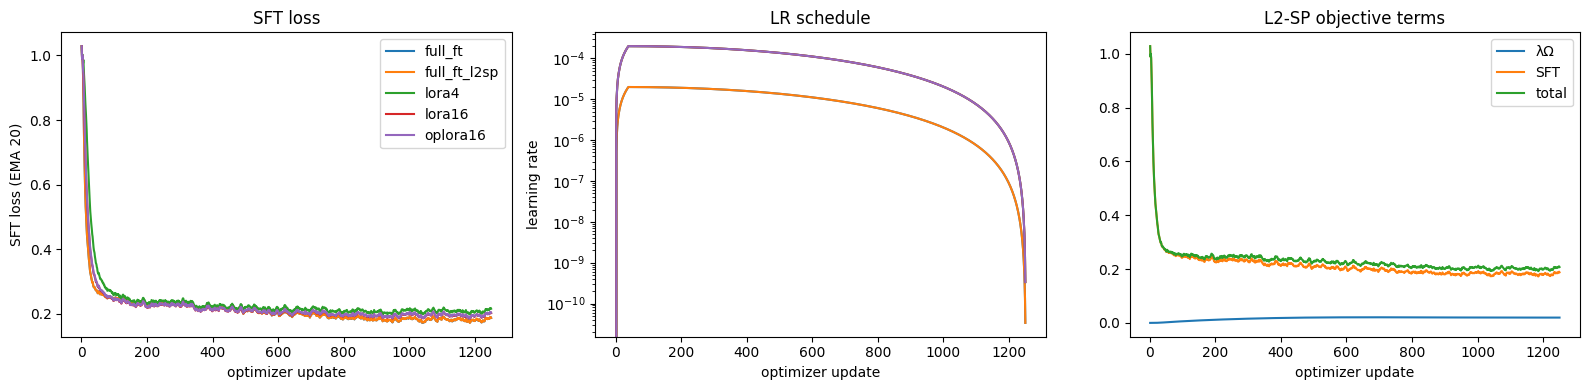

            run  trainable_params  train_time_h  peak_gpu_mem_GB  \
0       full_ft         596049920      2.517373        11.719666   
1  full_ft_l2sp         596049920      2.536836        12.802502   
2         lora4           2523136      3.061403         3.143606   
3        lora16          10092544      3.070276         3.256399   
4      oplora16          10092544      4.256433         3.561260   

   final_fp16_checkpoint_MB  adapter_export_MB  displacement_mid  \
0               1152.056302                NaN         10.026102   
1               1152.056302                NaN          6.442870   
2                       NaN           9.739036               NaN   
3                       NaN          38.614036               NaN   
4                       NaN          38.614036               NaN   

   displacement_final  reference_storage_MB  penalty_time_s  basis_storage_MB  \
0           10.663999              1136.875             NaN               NaN   
1            6.27594

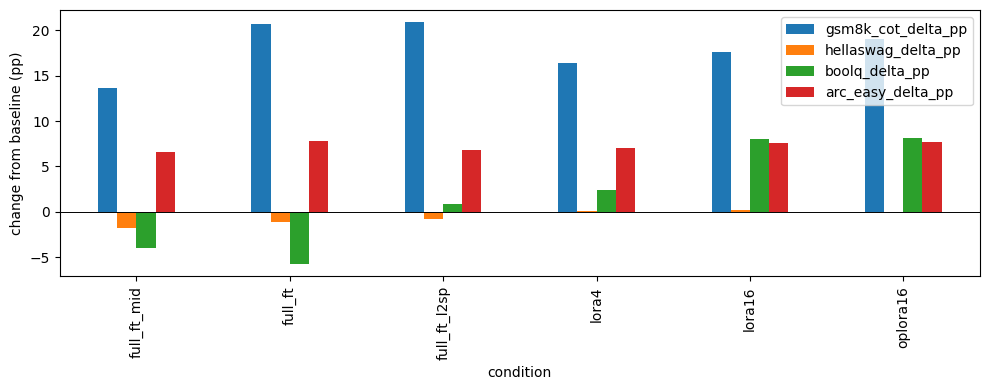

All Task 1 outputs are in /content/drive/MyDrive/ATML_PA3/task1


In [20]:
# 15. Aggregate tables and figures (saved to MyDrive/ATML_PA3/task1/results)
import matplotlib.pyplot as plt
RES = ROOT / "results"

# benchmark table with percentage-point changes from the shared baseline
rows = []
for c in CONDITIONS:
    r = {"condition": c}
    for t in EVAL_TASKS:
        f = ROOT / "eval" / c / f"{t}.json"
        if not f.exists(): continue
        m = jload(f)["metrics"]
        r[f"{t}"] = 100 * m[PRIMARY[t]]
        if "acc,none" in m and t != "boolq": r[f"{t}_raw_acc"] = 100 * m["acc,none"]
        if t == "gsm8k_cot":
            r["gsm8k_strict"] = 100 * m.get("exact_match,strict-match", float("nan"))
            r["gsm8k_trunc_%"] = 100 * m["truncation_rate"]; r["gsm8k_unextract_%"] = 100 * m["unextractable_rate_flexible"]
            r["gsm8k_mean_tokens"] = m["mean_response_tokens"]
    rows.append(r)
bench = pd.DataFrame(rows).set_index("condition")
if "baseline" in bench.index:
    for t in EVAL_TASKS:
        if t in bench: bench[f"{t}_delta_pp"] = bench[t] - bench.loc["baseline", t]
bench.round(2).to_csv(RES / "benchmarks.csv"); print(bench.round(2).T)

# learning curves
logs = {r: pd.read_json(ROOT / "runs" / r / "train_log.jsonl", lines=True)
        for r in RUNS if (ROOT / "runs" / r / "train_log.jsonl").exists()}
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for r, df in logs.items():
    ax[0].plot(df["update"], df["sft_loss"].ewm(span=20).mean(), label=r)
    ax[1].plot(df["update"], df["lr"], label=r)
ax[0].set(xlabel="optimizer update", ylabel="SFT loss (EMA 20)", title="SFT loss"); ax[0].legend()
ax[1].set(xlabel="optimizer update", ylabel="learning rate", yscale="log", title="LR schedule")
if "full_ft_l2sp" in logs:
    df = logs["full_ft_l2sp"]
    ax[2].plot(df["update"], df["lambda_omega"], label="λΩ"); ax[2].plot(df["update"], df["sft_loss"].ewm(span=20).mean(), label="SFT")
    ax[2].plot(df["update"], df["total_loss"].ewm(span=20).mean(), label="total"); ax[2].legend()
    ax[2].set(xlabel="optimizer update", title="L2-SP objective terms")
plt.tight_layout(); plt.savefig(RES / "learning_curves.png", dpi=150); plt.show()

# resources
resr = []
for r in RUNS:
    f = ROOT / "runs" / r / "resources.json"
    if f.exists(): resr.append(jload(f))
resdf = pd.DataFrame(resr)
cols = [c for c in ["run", "trainable_params", "train_time_h", "peak_gpu_mem_GB", "final_fp16_checkpoint_MB",
                    "adapter_export_MB", "displacement_mid", "displacement_final", "reference_storage_MB",
                    "penalty_time_s", "basis_storage_MB", "basis_preprocess_svd_time_s", "export_projection_time_s",
                    "skipped_updates", "gpu"] if c in resdf]
resdf[cols].to_csv(RES / "resources.csv", index=False); print(resdf[cols])

# benchmark bar chart (Δ pp vs baseline)
if "baseline" in bench.index:
    dcols = [f"{t}_delta_pp" for t in EVAL_TASKS if f"{t}_delta_pp" in bench]
    bench[dcols].drop(index="baseline").plot.bar(figsize=(10, 4)); plt.axhline(0, c="k", lw=.7)
    plt.ylabel("change from baseline (pp)"); plt.tight_layout(); plt.savefig(RES / "benchmark_deltas.png", dpi=150); plt.show()
print("All Task 1 outputs are in", ROOT)

In [21]:
import gzip, json
rd = lambda c, t: [json.loads(l) for l in gzip.open(ROOT / "eval" / c / f"{t}_samples.jsonl.gz", "rt")]
for c in CONDITIONS:   # BoolQ choices are ["no", "yes"]; majority class "yes" = 62.2%
    print(f"{c:13s} predicts 'yes' on {100 * np.mean([r['loglik'][1] > r['loglik'][0] for r in rd(c, 'boolq')]):.1f}% of BoolQ")
t2 = AutoTokenizer.from_pretrained(str(ROOT / "runs/full_ft/final"))
s = "Q: Janet has 1,234 apples.\n  A: \\boxed{42} — done!"
print("tokenizer identical:", tok(s)["input_ids"] == t2(s)["input_ids"])

baseline      predicts 'yes' on 57.8% of BoolQ
full_ft_mid   predicts 'yes' on 29.0% of BoolQ
full_ft       predicts 'yes' on 26.3% of BoolQ
full_ft_l2sp  predicts 'yes' on 39.7% of BoolQ
lora4         predicts 'yes' on 45.8% of BoolQ
lora16        predicts 'yes' on 59.5% of BoolQ
oplora16      predicts 'yes' on 57.9% of BoolQ


The tokenizer you are loading from '/content/drive/MyDrive/ATML_PA3/task1/runs/full_ft/final' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


tokenizer identical: True


In [22]:
from sklearn.metrics import roc_auc_score
for c in CONDITIONS:
    b = rd(c, "boolq"); y = np.array([str(r["target"]).strip().lower() in ("1", "yes", "true") for r in b])
    s = np.array([r["loglik"][1] - r["loglik"][0] for r in b]); p = s > 0
    tpr, tnr = p[y].mean(), (~p[~y]).mean()
    print(f"{c:13s} yes-labels {y.mean():.3f} | TPR {tpr:.3f} TNR {tnr:.3f} | balanced {100*(tpr+tnr)/2:.1f} | AUC {roc_auc_score(y, s):.3f}")

baseline      yes-labels 0.622 | TPR 0.678 TNR 0.586 | balanced 63.2 | AUC 0.685
full_ft_mid   yes-labels 0.622 | TPR 0.414 TNR 0.915 | balanced 66.5 | AUC 0.784
full_ft       yes-labels 0.622 | TPR 0.378 TNR 0.926 | balanced 65.2 | AUC 0.780
full_ft_l2sp  yes-labels 0.622 | TPR 0.540 TNR 0.838 | balanced 68.9 | AUC 0.777
lora4         yes-labels 0.622 | TPR 0.601 TNR 0.777 | balanced 68.9 | AUC 0.764
lora16        yes-labels 0.622 | TPR 0.757 TNR 0.670 | balanced 71.4 | AUC 0.781
oplora16      yes-labels 0.622 | TPR 0.744 TNR 0.693 | balanced 71.8 | AUC 0.784
